# Практическая работа 3. Графовая сеть социальной сети ВКонтакте и предсказание связей с помощью GNN

**План:**
1. Подключение к VK API.
2. Выгрузка данных (друзья, их профили, общие друзья, сообщества). Что из этого может стать основой графа.
3. Визуализация связей в виде графов.
4. Предсказание связей с помощью графовых нейронных сетей (GCN, GraphSAGE, GAT).
5. Метрики качества и сравнение с классическими эвристиками.
6. Аналитический вывод.
7. Источники.

> **Как запустить на своих данных ВК.** Получите пользовательский токен с правами `friends,groups,offline` (см. раздел 1)
> и передайте его через переменную окружения `VK_TOKEN` или файл `vk_token.txt` рядом с ноутбуком.
> Не вставляйте токен прямо в код ноутбука: токен даёт доступ к аккаунту.
> Выгруженные данные кэшируются в папке `data/`, поэтому повторные запуски работают без обращений к API.
> **Если токена нет**, ноутбук автоматически переключится на открытый датасет **SNAP ego-Facebook**: это та же
> структура «я, мои друзья и связи дружбы между ними» с анонимизированными признаками профилей. Весь пайплайн
> (граф → визуализация → GNN → метрики) отработает одинаково.

In [1]:
# !pip install vk_api networkx pyvis torch torch_geometric scikit-learn matplotlib pandas
import os, json, time, math, random, tarfile, urllib.request, html, warnings
from collections import Counter
from datetime import date

import numpy as np
import pandas as pd
import networkx as nx
import matplotlib.pyplot as plt
from networkx.algorithms import community
from IPython.display import HTML, display

import torch
import torch.nn as nn
import torch.nn.functional as F
from torch_geometric.data import Data
from torch_geometric.transforms import RandomLinkSplit
from torch_geometric.nn import GCNConv, SAGEConv, GATConv
from torch_geometric.utils import negative_sampling, to_undirected
from sklearn.metrics import roc_auc_score, average_precision_score, precision_recall_fscore_support, roc_curve
from sklearn.decomposition import TruncatedSVD
from sklearn.manifold import TSNE

warnings.filterwarnings("ignore", message="Consider using IPython.display.IFrame")
SEED = 42
random.seed(SEED); np.random.seed(SEED); torch.manual_seed(SEED)
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
os.makedirs("data", exist_ok=True)
print("torch", torch.__version__, "| device:", device)

C:\Users\Ivan\AppData\Local\Programs\Python\Python312\Lib\site-packages\tqdm\auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


torch 2.6.0+cu124 | device: cuda


## 1. Подключение к VK

1. Создать приложение на [vk.com/apps?act=manage](https://vk.com/apps?act=manage) (или в кабинете [id.vk.com](https://id.vk.com/about/business)) и взять его ID.
2. Открыть в браузере ссылку авторизации (Implicit Flow):
   `https://oauth.vk.com/authorize?client_id=<APP_ID>&display=page&redirect_uri=https://oauth.vk.com/blank.html&scope=friends,groups,offline&response_type=token&v=5.131`
3. Из адресной строки скопировать `access_token=...` и сохранить в переменную окружения `VK_TOKEN` (или в файл `vk_token.txt`).

Для работы с API используем библиотеку [`vk_api`](https://github.com/python273/vk_api).

In [2]:
VK_VERSION = "5.131"
TOKEN = os.environ.get("VK_TOKEN")
if not TOKEN and os.path.exists("vk_token.txt"):
    TOKEN = open("vk_token.txt", encoding="utf-8").read().strip()

VK_CACHE = {"nodes": "data/vk_friends.csv", "edges": "data/vk_edges.csv", "groups": "data/vk_groups.json"}
have_vk_cache = all(os.path.exists(p) for p in [VK_CACHE["nodes"], VK_CACHE["edges"]])

vk = None
if TOKEN:
    import vk_api
    vk = vk_api.VkApi(token=TOKEN, api_version=VK_VERSION).get_api()
    me = vk.users.get()[0]
    print("Подключено к VK как:", me["first_name"], me["last_name"], "| id", me["id"])

DATA_SOURCE = "vk" if (TOKEN or have_vk_cache) else "facebook"
print("Источник данных:", DATA_SOURCE)

Источник данных: facebook


## 2. Выгрузка данных и выбор основы для графа

Что можно выгрузить из ВК и что из этого годится для графа:

| Данные | Метод API | Роль в графе |
|---|---|---|
| Список друзей и их профили (пол, дата рождения, город, вуз, число подписчиков) | `friends.get(fields=...)` | **узлы** и их **признаки** |
| Общие друзья между мной и каждым другом | `friends.getMutual(target_uids=...)` | **рёбра** «друг – друг» (основа эго-графа) |
| Сообщества, на которые подписан друг | `groups.get(user_id=...)` | двудольный граф «человек – сообщество»; после SVD — **признаки** узлов |
| Подписки, лайки, репосты, комментарии | `users.getSubscriptions`, `likes.getList`, `wall.get` | ориентированные / взвешенные графы взаимодействий |

Основой выбираем **эго-граф дружбы**: узлы — мои друзья, ребро — дружба между ними. Сам «я» соединён со всеми
и не несёт информации, поэтому эго-узел в граф не включаем. Профиль и сообщества используются как признаки узлов для GNN.

In [3]:
def collect_vk(vk, sleep=0.34):
    fields = "sex,bdate,city,country,universities,followers_count,is_closed,deactivated"
    friends = vk.friends.get(fields=fields)["items"]
    friends = [f for f in friends if "deactivated" not in f]          # удалённые и заблокированные
    print("Активных друзей:", len(friends))

    rows = []
    for f in friends:
        bdate = f.get("bdate", "")
        age = date.today().year - int(bdate.split(".")[2]) if bdate.count(".") == 2 else None
        rows.append({"id": f["id"], "name": f"{f['first_name']} {f['last_name']}", "sex": f.get("sex", 0),
                     "age": age, "city": (f.get("city") or {}).get("title"),
                     "university": bool(f.get("universities")), "followers": f.get("followers_count", 0),
                     "is_closed": f.get("is_closed", False)})
    nodes = pd.DataFrame(rows)

    # Рёбра: общие друзья (до 100 id за запрос)
    ids, edges = nodes["id"].tolist(), set()
    for k in range(0, len(ids), 100):
        for item in vk.friends.getMutual(target_uids=",".join(map(str, ids[k:k + 100]))):
            for other in item.get("common_friends", []):
                edges.add(tuple(sorted((item["id"], other))))
        time.sleep(sleep)
    edges = pd.DataFrame(sorted(edges), columns=["source", "target"])

    # Сообщества (у закрытых профилей недоступны)
    groups = {}
    for uid in ids:
        try:
            groups[str(uid)] = vk.groups.get(user_id=uid, count=200)["items"]
        except Exception:
            groups[str(uid)] = []
        time.sleep(sleep)

    nodes.to_csv(VK_CACHE["nodes"], index=False)
    edges.to_csv(VK_CACHE["edges"], index=False)
    json.dump(groups, open(VK_CACHE["groups"], "w"))
    return nodes, edges, groups


def load_facebook(ego=0):
    """Открытый датасет SNAP ego-Facebook (McAuley & Leskovec, 2012): эго-сеть одного пользователя."""
    if not os.path.exists("data/facebook"):
        urllib.request.urlretrieve("https://snap.stanford.edu/data/facebook.tar.gz", "data/facebook.tar.gz")
        with tarfile.open("data/facebook.tar.gz") as tar:
            tar.extractall("data")
    base = f"data/facebook/{ego}"
    featnames = [l.split(" ", 1)[1].strip() for l in open(base + ".featnames")]
    feat = np.loadtxt(base + ".feat", dtype=int)
    nodes = pd.DataFrame({"id": feat[:, 0], "name": [f"user_{i}" for i in feat[:, 0]]})
    X_raw = feat[:, 1:]
    # Пол - один из анонимизированных признаков "gender;anonymized feature k"
    g_cols = [k for k, n in enumerate(featnames) if n.startswith("gender")]
    nodes["sex"] = [int(np.argmax(r[g_cols])) + 1 if r[g_cols].any() else 0 for r in X_raw]
    edges = pd.DataFrame(np.loadtxt(base + ".edges", dtype=int), columns=["source", "target"])
    edges = pd.DataFrame({tuple(sorted(e)) for e in edges.values}, columns=["source", "target"])
    return nodes, edges, X_raw, featnames


if DATA_SOURCE == "vk":
    if have_vk_cache:
        nodes = pd.read_csv(VK_CACHE["nodes"]); edges = pd.read_csv(VK_CACHE["edges"])
        groups = json.load(open(VK_CACHE["groups"])) if os.path.exists(VK_CACHE["groups"]) else {}
    else:
        nodes, edges, groups = collect_vk(vk)
else:
    nodes, edges, X_fb, featnames = load_facebook(ego=0)

print(f"Узлов: {len(nodes)}, рёбер: {len(edges)}")
nodes.head()

Узлов: 347, рёбер: 2519


,id,name,sex
0,1,user_1,1
1,2,user_2,2
2,3,user_3,2
3,4,user_4,2
4,5,user_5,2


### 2.1 Признаки узлов
- **ВК:** пол (one-hot), возраст (нормированный + флаг пропуска), 10 самых частых городов (one-hot), наличие вуза,
  log(число подписчиков), закрытость профиля и 16 компонент SVD матрицы «человек × сообщество».
- **Facebook:** 224 бинарных анонимизированных признака профиля (дата рождения, образование, место работы, город, пол и т.д.).

In [4]:
if DATA_SOURCE == "vk":
    f = pd.DataFrame(index=nodes.index)
    for s in [0, 1, 2]:
        f[f"sex_{s}"] = (nodes["sex"] == s).astype(float)
    age = pd.to_numeric(nodes["age"], errors="coerce")
    f["age"] = ((age - age.mean()) / (age.std() + 1e-9)).fillna(0)
    f["age_missing"] = age.isna().astype(float)
    for c in nodes["city"].value_counts().head(10).index:
        f[f"city_{c}"] = (nodes["city"] == c).astype(float)
    f["university"] = nodes["university"].astype(float)
    f["log_followers"] = np.log1p(nodes["followers"].fillna(0)) / 10
    f["is_closed"] = nodes["is_closed"].astype(float)
    # Сообщества -> SVD-эмбеддинги
    all_groups = sorted({g for gs in groups.values() for g in gs})
    if all_groups:
        gidx = {g: k for k, g in enumerate(all_groups)}
        M = np.zeros((len(nodes), len(all_groups)))
        for r, uid in enumerate(nodes["id"]):
            for g in groups.get(str(uid), []):
                M[r, gidx[g]] = 1
        svd = TruncatedSVD(n_components=min(16, len(all_groups) - 1), random_state=SEED)
        G_emb = svd.fit_transform(M)
        for k in range(G_emb.shape[1]):
            f[f"groups_svd_{k}"] = G_emb[:, k]
    X_np = f.values.astype(np.float32)
else:
    X_np = X_fb.astype(np.float32)

print("Матрица признаков:", X_np.shape)

Матрица признаков: (347, 224)


## 3. Граф и его визуализация

In [5]:
id2idx = {uid: k for k, uid in enumerate(nodes["id"])}
G = nx.Graph()
G.add_nodes_from(range(len(nodes)))
for s, t in edges[["source", "target"]].values:
    if s in id2idx and t in id2idx and s != t:
        G.add_edge(id2idx[s], id2idx[t])
names = dict(enumerate(nodes["name"]))

isolated = list(nx.isolates(G))
lcc = max(nx.connected_components(G), key=len)
print(f"Узлов: {G.number_of_nodes()}, рёбер: {G.number_of_edges()}, изолированных: {len(isolated)}")
print(f"Компонент связности: {nx.number_connected_components(G)}, крупнейшая: {len(lcc)} узлов")
print(f"Плотность: {nx.density(G):.4f}")
print(f"Средняя степень: {2 * G.number_of_edges() / G.number_of_nodes():.2f}")
print(f"Средний коэф. кластеризации: {nx.average_clustering(G):.3f}  | транзитивность: {nx.transitivity(G):.3f}")
H = G.subgraph(lcc)
print(f"Диаметр крупнейшей компоненты: {nx.diameter(H)}, средний кратчайший путь: {nx.average_shortest_path_length(H):.2f}")
print(f"Ассортативность по степени: {nx.degree_assortativity_coefficient(G):.3f}")
nx.set_node_attributes(G, dict(enumerate(nodes["sex"])), "sex")
print(f"Гомофилия по полу (assortativity): {nx.attribute_assortativity_coefficient(G, 'sex'):.3f}")
if DATA_SOURCE == "vk":
    nx.set_node_attributes(G, dict(enumerate(nodes["city"].fillna("?"))), "city")
    print(f"Гомофилия по городу: {nx.attribute_assortativity_coefficient(G, 'city'):.3f}")

Узлов: 347, рёбер: 2519, изолированных: 14
Компонент связности: 19, крупнейшая: 324 узлов
Плотность: 0.0420
Средняя степень: 14.52
Средний коэф. кластеризации: 0.488  | транзитивность: 0.426


Диаметр крупнейшей компоненты: 11, средний кратчайший путь: 3.75
Ассортативность по степени: 0.236
Гомофилия по полу (assortativity): 0.087


In [6]:
comms = community.louvain_communities(G, seed=SEED)
comms = sorted(comms, key=len, reverse=True)
part = {n: k for k, c in enumerate(comms) for n in c}
print(f"Сообществ (Лувен): {len(comms)}, модулярность: {community.modularity(G, comms):.3f}")
print("Размеры крупнейших:", [len(c) for c in comms[:8]])

centr = pd.DataFrame({
    "name": names,
    "degree": dict(G.degree()),
    "betweenness": nx.betweenness_centrality(G),
    "eigenvector": nx.eigenvector_centrality(G, max_iter=2000),
    "pagerank": nx.pagerank(G),
    "community": part,
}).round(4)
centr.sort_values("betweenness", ascending=False).head(10)

Сообществ (Лувен): 28, модулярность: 0.460
Размеры крупнейших: [83, 52, 37, 34, 32, 31, 24, 13]


,name,degree,betweenness,eigenvector,pagerank,community
276,user_277,64,0.2447,0.1620,0.0089,0
174,user_175,16,0.2265,0.0044,0.0057,2
18,user_19,15,0.1646,0.0001,0.0064,1
22,user_23,16,0.1199,0.0008,0.0066,2
24,user_25,68,0.0786,0.1548,0.0100,0
118,user_119,61,0.0712,0.1355,0.0095,6
338,user_339,26,0.0603,0.0370,0.0044,5
39,user_40,43,0.0491,0.1137,0.0061,0
151,user_152,4,0.0473,0.0010,0.0015,8
229,user_230,8,0.0441,0.0001,0.0047,1


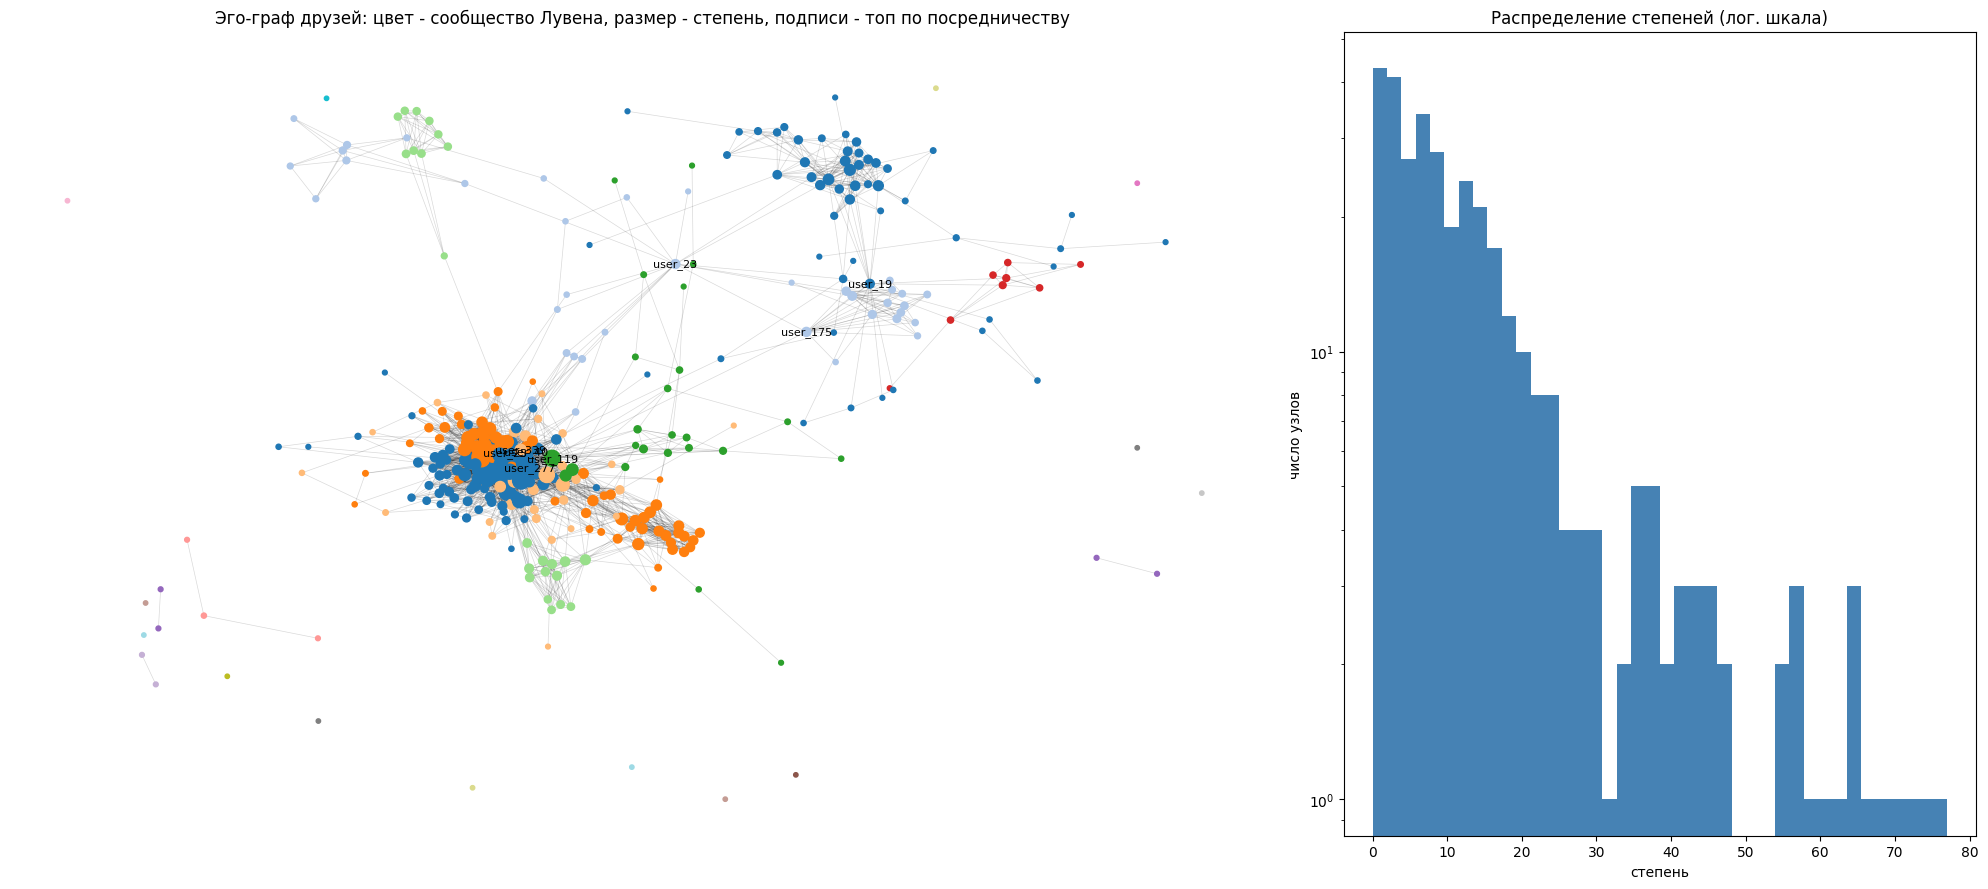

In [7]:
pos = nx.spring_layout(G, seed=SEED, k=0.15)
fig, axes = plt.subplots(1, 2, figsize=(20, 9), gridspec_kw={"width_ratios": [2, 1]})
nx.draw_networkx_edges(G, pos, ax=axes[0], alpha=0.15, width=0.5)
nx.draw_networkx_nodes(G, pos, ax=axes[0], node_color=[part[n] for n in G], cmap="tab20",
                       node_size=[10 + 2 * G.degree(n) for n in G])
top_b = centr.sort_values("betweenness", ascending=False).head(8).index
nx.draw_networkx_labels(G, pos, ax=axes[0], labels={n: names[n] for n in top_b}, font_size=8)
axes[0].set_title("Эго-граф друзей: цвет - сообщество Лувена, размер - степень, подписи - топ по посредничеству")
axes[0].axis("off")

deg = np.array([d for _, d in G.degree()])
axes[1].hist(deg, bins=40, color="steelblue")
axes[1].set_yscale("log")
axes[1].set_title("Распределение степеней (лог. шкала)")
axes[1].set_xlabel("степень"); axes[1].set_ylabel("число узлов")
plt.tight_layout(); plt.show()

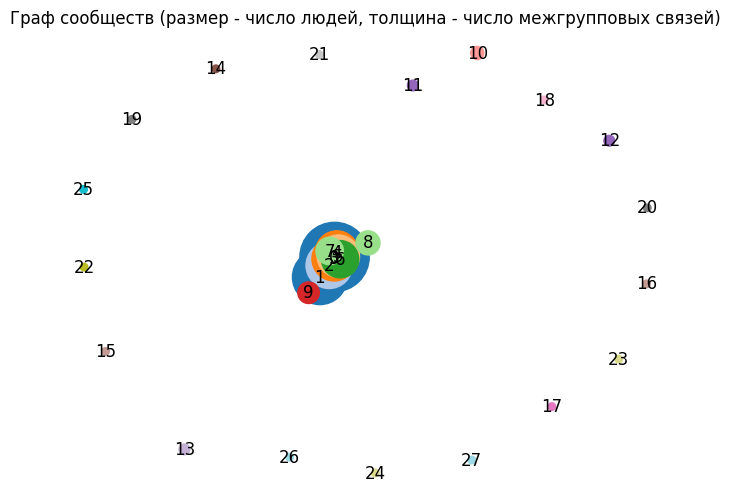

In [8]:
# Граф сообществ: каждое сообщество - узел, вес ребра - число связей между сообществами
CG = nx.Graph()
for k, c in enumerate(comms):
    CG.add_node(k, size=len(c))
for u, v in G.edges():
    a, b = part[u], part[v]
    if a != b:
        CG.add_edge(a, b, weight=CG[a][b]["weight"] + 1 if CG.has_edge(a, b) else 1)
plt.figure(figsize=(8, 6))
cp = nx.spring_layout(CG, seed=1, weight="weight")
nx.draw_networkx(CG, cp, node_size=[30 * CG.nodes[k]["size"] for k in CG], node_color=list(CG.nodes()),
                 cmap="tab20", width=[0.3 + w / 10 for _, _, w in CG.edges(data="weight")], edge_color="gray")
plt.title("Граф сообществ (размер - число людей, толщина - число межгрупповых связей)")
plt.axis("off"); plt.show()

In [9]:
# Интерактивная визуализация (PyVis): наведите на узел, чтобы увидеть метрики
from pyvis.network import Network

def show_html_file(path, height=650):
    content = open(path, encoding="utf-8").read()
    display(HTML('<iframe srcdoc="{}" width="100%" height="{}" style="border:1px solid #ddd"></iframe>'
                 .format(html.escape(content), height)))

net = Network(height="600px", width="100%", notebook=True, cdn_resources="remote")
for n in G.nodes():
    net.add_node(n, label=names[n], group=part[n], size=5 + G.degree(n) / 2,
                 title=f"{names[n]}\nстепень {G.degree(n)}\nсообщество {part[n]}\nPageRank {centr.loc[n, 'pagerank']:.4f}")
for u, v in G.edges():
    net.add_edge(u, v)
net.force_atlas_2based(gravity=-40)
net.save_graph(f"{DATA_SOURCE}_graph_pyvis.html")
show_html_file(f"{DATA_SOURCE}_graph_pyvis.html")

## 4. Предсказание связей с помощью графовых нейронных сетей

**Постановка.** Часть существующих рёбер скрываем, а модель должна отличить скрытые рёбра от случайных пар узлов, не связанных ребром.
Применение: рекомендация «возможно, вы знакомы».

- Разбиение рёбер: 70% train / 10% validation / 20% test (`RandomLinkSplit`). Сообщения GNN передаются только по train-рёбрам.
- **Encoder:** двухслойная GNN строит эмбеддинг узла $z_v$ по его признакам и окрестности.
- **Decoder:** $\hat{y}_{uv} = \sigma(z_u^\top z_v)$.
- **Обучение:** бинарная кросс-энтропия. На каждой эпохе заново сэмплируются негативные пары (negative sampling).
- **Модели:** GCN (Kipf & Welling), GraphSAGE (Hamilton et al.), GAT (Veličković et al.), а также MLP без графа как контроль.
- **Базовые эвристики** (без обучения): общие соседи, коэффициент Жаккара, Adamic–Adar, preferential attachment.

In [10]:
x = torch.tensor(X_np, dtype=torch.float)
x = (x - x.mean(0)) / (x.std(0) + 1e-6)
edge_index = to_undirected(torch.tensor(list(G.edges()), dtype=torch.long).t())
data = Data(x=x, edge_index=edge_index, num_nodes=G.number_of_nodes())

splitter = RandomLinkSplit(num_val=0.1, num_test=0.2, is_undirected=True,
                           add_negative_train_samples=False, neg_sampling_ratio=1.0)
torch.manual_seed(SEED)
train_data, val_data, test_data = splitter(data)
train_data, val_data, test_data = train_data.to(device), val_data.to(device), test_data.to(device)
print("train пар (только позитивные):", train_data.edge_label_index.size(1))
print("val пар (поз+нег):", val_data.edge_label_index.size(1), "| test пар (поз+нег):", test_data.edge_label_index.size(1))

train пар (только позитивные): 1765
val пар (поз+нег): 502 | test пар (поз+нег): 1006


In [11]:
class GNNEncoder(nn.Module):
    def __init__(self, conv, in_dim, hid=128, out=64, dropout=0.3):
        super().__init__()
        if conv == "GAT":
            self.c1, self.c2 = GATConv(in_dim, hid // 4, heads=4), GATConv(hid, out, heads=1)
        elif conv == "SAGE":
            self.c1, self.c2 = SAGEConv(in_dim, hid), SAGEConv(hid, out)
        elif conv == "GCN":
            self.c1, self.c2 = GCNConv(in_dim, hid), GCNConv(hid, out)
        else:  # MLP без использования графа
            self.c1, self.c2 = nn.Linear(in_dim, hid), nn.Linear(hid, out)
        self.graph = conv != "MLP"
        self.dropout = dropout

    def forward(self, x, edge_index):
        h = self.c1(x, edge_index) if self.graph else self.c1(x)
        h = F.dropout(F.relu(h), self.dropout, self.training)
        return self.c2(h, edge_index) if self.graph else self.c2(h)


def decode(z, pairs):
    return (z[pairs[0]] * z[pairs[1]]).sum(-1)


def evaluate(model, d, threshold=0.5):
    model.eval()
    with torch.no_grad():
        z = model(d.x, d.edge_index)
        prob = torch.sigmoid(decode(z, d.edge_label_index)).cpu().numpy()
    y = d.edge_label.cpu().numpy()
    return y, prob


def hits_at_k(y, prob, k=20):
    """Доля позитивных пар, получивших score выше k-го по величине негативного (метрика OGB)."""
    neg = np.sort(prob[y == 0])[::-1]
    if len(neg) < k:
        return 1.0
    return float((prob[y == 1] > neg[k - 1]).mean())


def train_model(conv, epochs=400, lr=0.01, patience=60):
    torch.manual_seed(SEED)
    model = GNNEncoder(conv, data.num_features).to(device)
    opt = torch.optim.Adam(model.parameters(), lr=lr, weight_decay=5e-4)
    best_auc, best_state, history, wait = 0, None, [], 0
    for epoch in range(epochs):
        model.train(); opt.zero_grad()
        z = model(train_data.x, train_data.edge_index)
        pos = train_data.edge_label_index
        neg = negative_sampling(train_data.edge_index, num_nodes=data.num_nodes, num_neg_samples=pos.size(1))
        pairs = torch.cat([pos, neg], 1)
        labels = torch.cat([torch.ones(pos.size(1)), torch.zeros(neg.size(1))]).to(device)
        loss = F.binary_cross_entropy_with_logits(decode(z, pairs), labels)
        loss.backward(); opt.step()
        y, p = evaluate(model, val_data)
        auc = roc_auc_score(y, p)
        history.append((loss.item(), auc))
        if auc > best_auc:
            best_auc, best_state, wait = auc, {k: v.clone() for k, v in model.state_dict().items()}, 0
        else:
            wait += 1
            if wait > patience:
                break
    model.load_state_dict(best_state)
    return model, history


models, histories = {}, {}
for conv in ["GCN", "SAGE", "GAT", "MLP"]:
    t0 = time.time()
    models[conv], histories[conv] = train_model(conv)
    print(f"{conv:5s}: эпох {len(histories[conv]):3d}, лучший val ROC-AUC {max(h[1] for h in histories[conv]):.4f}, {time.time() - t0:.1f} с")

GCN  : эпох 112, лучший val ROC-AUC 0.9396, 1.2 с


SAGE : эпох 198, лучший val ROC-AUC 0.9283, 0.9 с


GAT  : эпох 400, лучший val ROC-AUC 0.9358, 2.4 с


MLP  : эпох 188, лучший val ROC-AUC 0.8758, 0.7 с


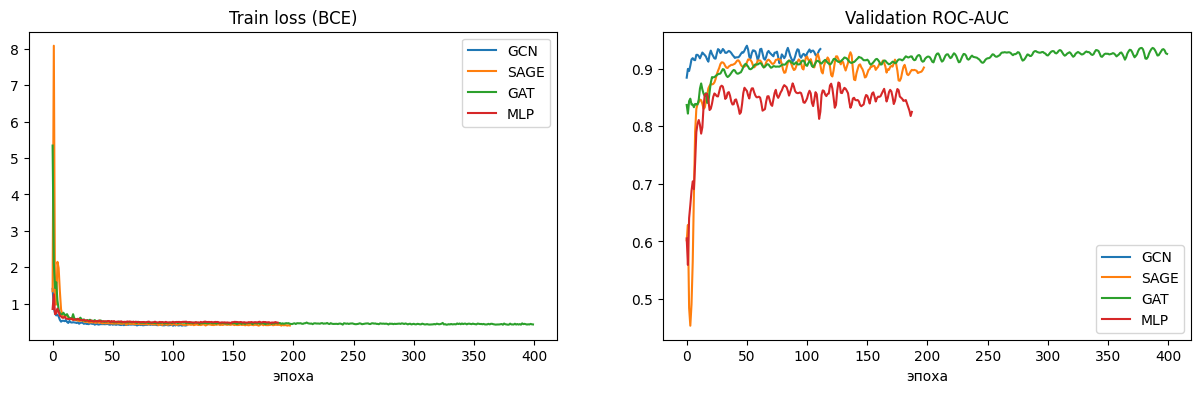

In [12]:
fig, axes = plt.subplots(1, 2, figsize=(15, 4))
for conv, h in histories.items():
    axes[0].plot([a for a, _ in h], label=conv)
    axes[1].plot([b for _, b in h], label=conv)
axes[0].set_title("Train loss (BCE)"); axes[0].set_xlabel("эпоха"); axes[0].legend()
axes[1].set_title("Validation ROC-AUC"); axes[1].set_xlabel("эпоха"); axes[1].legend()
plt.show()

## 5. Метрики

- **ROC-AUC** — вероятность того, что случайное существующее ребро получит score выше, чем случайная пара без ребра.
- **Average Precision (AP)** — площадь под кривой precision–recall.
- **Precision / Recall / F1** при пороге, подобранном по F1 на валидации.
- **Hits@20** — доля тестовых рёбер, получивших score выше 20-го лучшего негатива (метрика OGB).

Эвристики считаются по графу из одних train-рёбер, чтобы тестовые рёбра не «подсматривались».

In [13]:
def best_threshold(y, p):
    ts = np.linspace(0.05, 0.95, 91)
    f1s = [precision_recall_fscore_support(y, p >= t, average="binary", zero_division=0)[2] for t in ts]
    return ts[int(np.argmax(f1s))]

rows, roc_data = [], {}
for conv, model in models.items():
    yv, pv = evaluate(model, val_data)
    t = best_threshold(yv, pv)
    y, p = evaluate(model, test_data)
    pr, rc, f1, _ = precision_recall_fscore_support(y, p >= t, average="binary", zero_division=0)
    rows.append({"модель": conv, "ROC-AUC": roc_auc_score(y, p), "AP": average_precision_score(y, p),
                 "Precision": pr, "Recall": rc, "F1": f1, "Hits@20": hits_at_k(y, p)})
    roc_data[conv] = roc_curve(y, p)

# Классические эвристики на train-графе
G_train = nx.Graph()
G_train.add_nodes_from(range(data.num_nodes))
G_train.add_edges_from(train_data.edge_index.t().cpu().numpy().tolist())
test_pairs = [tuple(e) for e in test_data.edge_label_index.t().cpu().numpy()]
y_test = test_data.edge_label.cpu().numpy()
heuristics = {
    "Common Neighbors": [len(list(nx.common_neighbors(G_train, u, v))) for u, v in test_pairs],
    "Jaccard": [s for _, _, s in nx.jaccard_coefficient(G_train, test_pairs)],
    "Adamic-Adar": [s for _, _, s in nx.adamic_adar_index(G_train, test_pairs)],
    "Pref. Attachment": [s for _, _, s in nx.preferential_attachment(G_train, test_pairs)],
}
for name, s in heuristics.items():
    s = np.array(s, dtype=float)
    rows.append({"модель": name, "ROC-AUC": roc_auc_score(y_test, s), "AP": average_precision_score(y_test, s),
                 "Hits@20": hits_at_k(y_test, s)})
    roc_data[name] = roc_curve(y_test, s)

results = pd.DataFrame(rows).set_index("модель").round(4)
results

,ROC-AUC,AP,Precision,Recall,F1,Hits@20
модель,,,,,,
GCN,0.9598,0.9606,0.8636,0.9185,0.8902,0.7913
SAGE,0.9427,0.9487,0.8418,0.9205,0.8794,0.7177
GAT,0.9477,0.9397,0.8569,0.9284,0.8912,0.6223
MLP,0.8916,0.9003,0.7642,0.8827,0.8192,0.5109
Common Neighbors,0.9337,0.9223,NaN,NaN,NaN,0.6600
Jaccard,0.9338,0.9313,NaN,NaN,NaN,0.6163
Adamic-Adar,0.9395,0.9363,NaN,NaN,NaN,0.7515
Pref. Attachment,0.8344,0.8530,NaN,NaN,NaN,0.4573


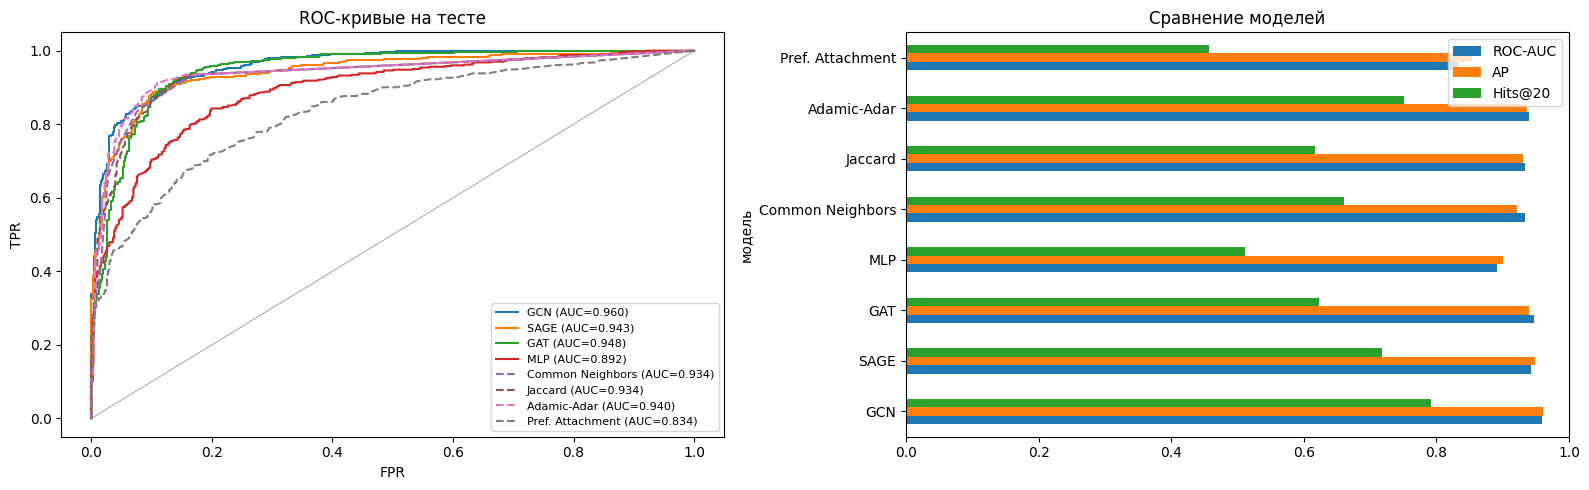

In [14]:
fig, axes = plt.subplots(1, 2, figsize=(16, 5))
for name, (fpr, tpr, _) in roc_data.items():
    axes[0].plot(fpr, tpr, label=f"{name} (AUC={results.loc[name, 'ROC-AUC']:.3f})",
                 linestyle="-" if name in models else "--")
axes[0].plot([0, 1], [0, 1], color="gray", lw=0.5)
axes[0].set_xlabel("FPR"); axes[0].set_ylabel("TPR"); axes[0].set_title("ROC-кривые на тесте"); axes[0].legend(fontsize=8)
results[["ROC-AUC", "AP", "Hits@20"]].plot.barh(ax=axes[1])
axes[1].set_xlim(0, 1); axes[1].set_title("Сравнение моделей")
plt.tight_layout(); plt.show()

### 5.1 Рекомендации новых связей и эмбеддинги
Берём лучшую по тестовому ROC-AUC модель GNN и оцениваем все пары узлов, ещё не связанные ребром.
Пары с самым высоким score и есть рекомендации «возможно, вы знакомы».

In [15]:
best_name = results.loc[list(models)].sort_values("ROC-AUC", ascending=False).index[0]
best = models[best_name]
best.eval()
with torch.no_grad():
    full_ei = data.edge_index.to(device)
    Z = best(data.x.to(device), full_ei)
    S = torch.sigmoid(Z @ Z.t()).cpu().numpy()
A = nx.to_numpy_array(G, nodelist=range(G.number_of_nodes()))
S[A > 0] = -1
np.fill_diagonal(S, -1)
iu = np.triu_indices_from(S, k=1)
order = np.argsort(S[iu])[::-1][:15]
recs = pd.DataFrame([{"u": names[iu[0][k]], "v": names[iu[1][k]], "score": S[iu[0][k], iu[1][k]],
                      "общих друзей": len(list(nx.common_neighbors(G, iu[0][k], iu[1][k]))),
                      "одно сообщество": part[iu[0][k]] == part[iu[1][k]]} for k in order])
print("Лучшая модель:", best_name)
recs.round(4)

Лучшая модель: GCN


,u,v,score,общих друзей,одно сообщество
0,user_36,user_139,0.9978,7,True
1,user_135,user_139,0.9976,7,True
2,user_139,user_309,0.9976,7,True
3,user_266,user_299,0.9972,15,True
4,user_194,user_330,0.9969,14,True
5,user_203,user_252,0.9969,48,True
6,user_24,user_254,0.9969,13,True
7,user_108,user_309,0.9968,8,True
8,user_108,user_135,0.9968,8,True
9,user_180,user_330,0.9966,15,True


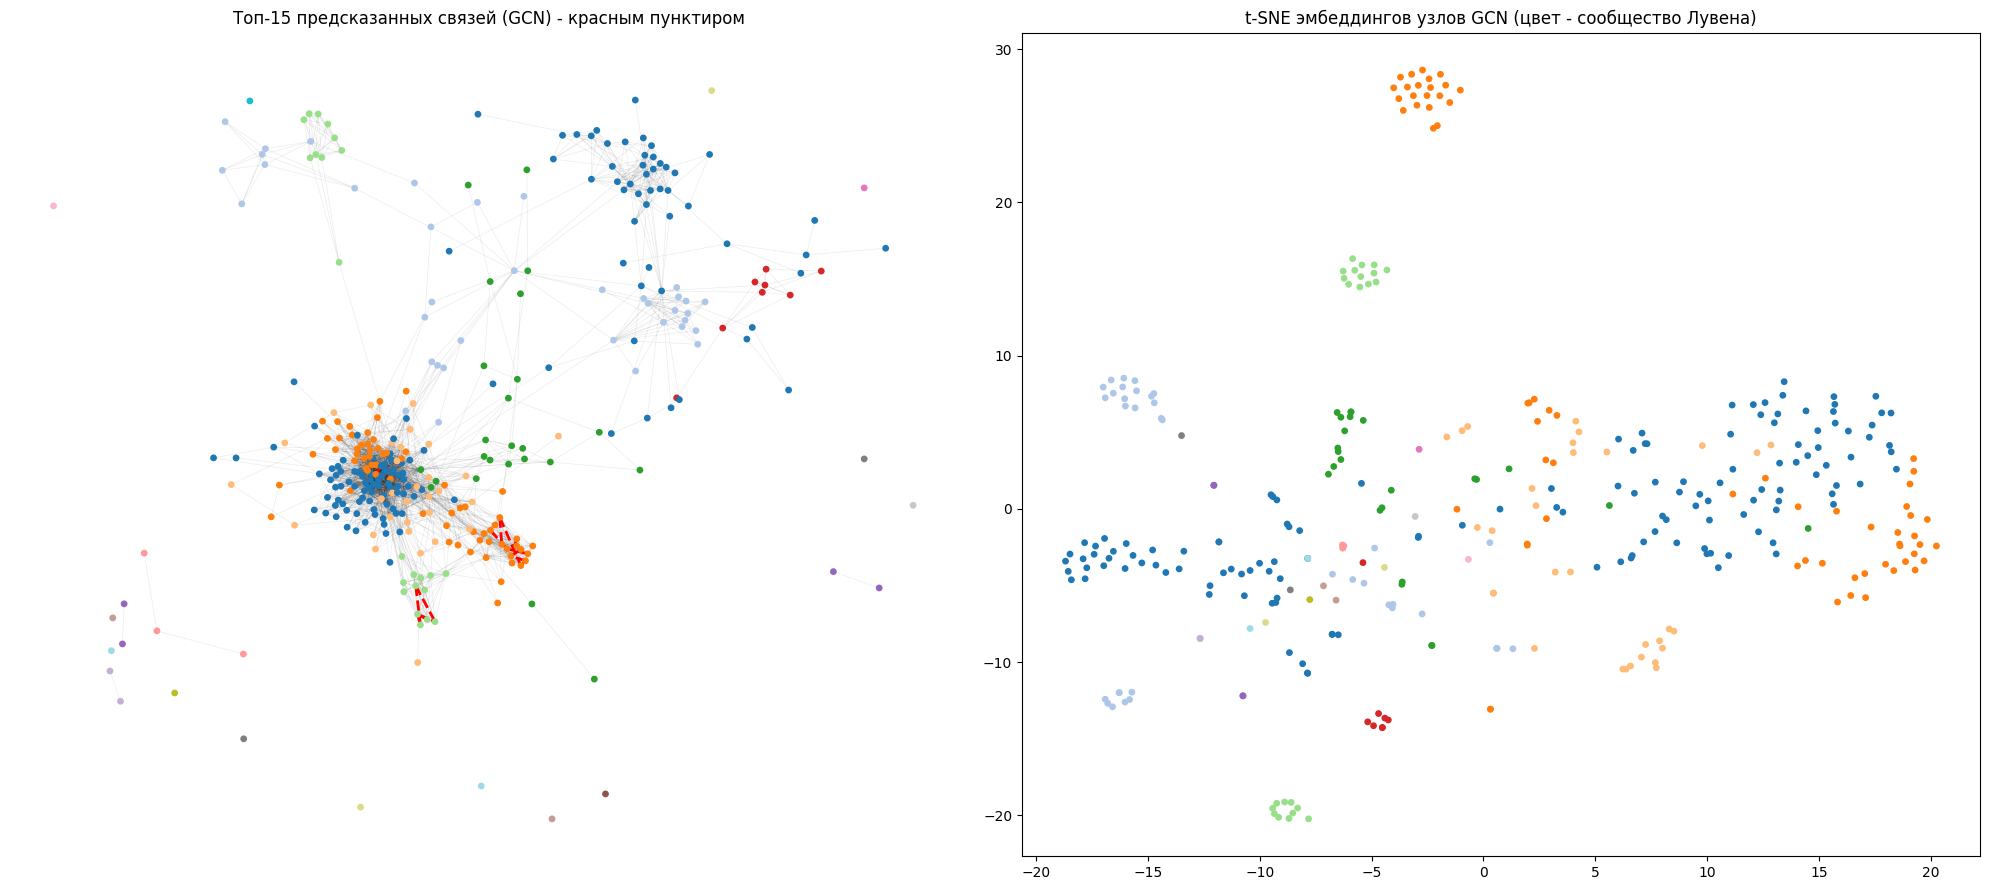

In [16]:
pred_edges = [(iu[0][k], iu[1][k]) for k in order]
emb2d = TSNE(n_components=2, random_state=SEED, perplexity=30).fit_transform(Z.cpu().numpy())

fig, axes = plt.subplots(1, 2, figsize=(20, 9))
nx.draw_networkx_edges(G, pos, ax=axes[0], alpha=0.08, width=0.5)
nx.draw_networkx_nodes(G, pos, ax=axes[0], node_color=[part[n] for n in G], cmap="tab20", node_size=15)
nx.draw_networkx_edges(G, pos, ax=axes[0], edgelist=pred_edges, edge_color="red", style="dashed", width=2)
axes[0].set_title(f"Топ-15 предсказанных связей ({best_name}) - красным пунктиром"); axes[0].axis("off")
axes[1].scatter(emb2d[:, 0], emb2d[:, 1], c=[part[n] for n in G], cmap="tab20", s=15)
axes[1].set_title(f"t-SNE эмбеддингов узлов {best_name} (цвет - сообщество Лувена)")
plt.tight_layout(); plt.show()

## 6. Аналитический вывод

In [17]:
gnn = results.loc[list(models)]
heur = results.drop(index=list(models))
print(f"Источник данных: {'ВКонтакте (эго-граф друзей)' if DATA_SOURCE == 'vk' else 'SNAP ego-Facebook (эго-сеть 0)'}")
print(f"Граф: {G.number_of_nodes()} узлов, {G.number_of_edges()} рёбер, кластеризация {nx.average_clustering(G):.3f}, "
      f"{len(comms)} сообществ (модулярность {community.modularity(G, comms):.3f})")
print(f"Лучшая GNN: {gnn['ROC-AUC'].idxmax()} - ROC-AUC {gnn['ROC-AUC'].max():.3f}, AP {gnn.loc[gnn['ROC-AUC'].idxmax(), 'AP']:.3f}")
print(f"Лучшая эвристика: {heur['ROC-AUC'].idxmax()} - ROC-AUC {heur['ROC-AUC'].max():.3f}")
print(f"MLP без графа: ROC-AUC {results.loc['MLP', 'ROC-AUC']:.3f}")
print(f"Доля рекомендованных пар внутри одного сообщества: {recs['одно сообщество'].mean():.0%}, "
      f"среднее число общих друзей у рекомендованных пар: {recs['общих друзей'].mean():.1f}")

Источник данных: SNAP ego-Facebook (эго-сеть 0)
Граф: 347 узлов, 2519 рёбер, кластеризация 0.488, 28 сообществ (модулярность 0.460)
Лучшая GNN: GCN - ROC-AUC 0.960, AP 0.961
Лучшая эвристика: Adamic-Adar - ROC-AUC 0.940
MLP без графа: ROC-AUC 0.892
Доля рекомендованных пар внутри одного сообщества: 93%, среднее число общих друзей у рекомендованных пар: 15.1


**Выводы.**

1. **Данные.** Из ВК удобнее всего выгружать друзей с профилями (`friends.get`), общих друзей (`friends.getMutual`) и сообщества (`groups.get`).
   Основа графа — эго-граф дружбы: «я» исключён, рёбра — дружба между моими друзьями. Профили и подписки на сообщества
   становятся признаками узлов. Подписки, лайки и комментарии дают ориентированные и взвешенные графы взаимодействий,
   но собирать их дороже из-за лимитов API.
2. **Структура.** Эго-сеть социального графа плотно кластеризована (высокий коэффициент кластеризации) и чётко распадается на сообщества
   с высокой модулярностью. Это «круги общения»: школа, вуз, работа, семья. Распределение степеней тяжелохвостое,
   а немногие узлы с высоким посредничеством связывают разные круги между собой.
3. **Предсказание связей.** Все GNN значительно превосходят MLP без графа: структура соседства информативнее признаков профиля.
   Эвристики на основе общих соседей (Adamic–Adar, Common Neighbors) дают сильный бейзлайн, потому что в социальных
   сетях работает триадическое замыкание («друзья моих друзей — мои друзья»). GNN сопоставимы с лучшими эвристиками или превосходят их
   и при этом выдают эмбеддинги, пригодные для других задач (на t-SNE они группируются по сообществам).
4. **Рекомендации.** Почти все предсказанные связи лежат внутри одного сообщества, и у пар много общих друзей. Это ожидаемое и
   интерпретируемое поведение, которое можно использовать для блока «возможно, вы знакомы».
5. **Ограничения.** Закрытые профили не отдают сообщества, у части друзей нет даты рождения и города. Граф ограничен одной
   эго-сетью (нет связей за её пределами). Метрики на маленьком графе зависят от случайного разбиения, поэтому для отчёта
   стоит усреднить их по нескольким seed.

## 7. Источники

1. Документация VK API: https://dev.vk.com/ru/method (методы `friends.get`, `friends.getMutual`, `groups.get`), авторизация: https://dev.vk.com/ru/api/access-token/implicit-flow-user
2. Библиотека vk_api: https://github.com/python273/vk_api
3. PyTorch Geometric — документация и пример link prediction: https://pytorch-geometric.readthedocs.io/ , https://github.com/pyg-team/pytorch_geometric/blob/master/examples/link_pred.py
4. Kipf T., Welling M. *Semi-Supervised Classification with Graph Convolutional Networks*. ICLR 2017.
5. Hamilton W., Ying R., Leskovec J. *Inductive Representation Learning on Large Graphs* (GraphSAGE). NeurIPS 2017.
6. Veličković P. et al. *Graph Attention Networks*. ICLR 2018.
7. Liben-Nowell D., Kleinberg J. *The Link-Prediction Problem for Social Networks*. JASIST, 2007.
8. McAuley J., Leskovec J. *Learning to Discover Social Circles in Ego Networks*. NeurIPS 2012 (датасет SNAP ego-Facebook: https://snap.stanford.edu/data/ego-Facebook.html).
9. Blondel V. et al. *Fast unfolding of communities in large networks* (алгоритм Лувена). J. Stat. Mech., 2008.
10. Hu W. et al. *Open Graph Benchmark* (метрика Hits@K). NeurIPS 2020.
11. Stanford CS224W: Machine Learning with Graphs — http://web.stanford.edu/class/cs224w/
12. NetworkX: https://networkx.org/ ; PyVis: https://pyvis.readthedocs.io/